# Task 17: Advanced Scatter Plots

## Objective
To visualize relationships between numerical features using scatter plots.
Point sizes and colors are dynamically adjusted according to age and target.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../../datasets/heart.csv")

print("Dataset Shape:", df.shape)
print(df.head())
print("\nColumns:", list(df.columns))

Dataset Shape: (1025, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [3]:
required_columns = ["age", "chol", "thalach", "target"]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Required column '{col}' not found in dataset.")

plot_df = df[required_columns].copy()

for col in required_columns:
    plot_df[col] = pd.to_numeric(plot_df[col], errors="coerce")

plot_df = plot_df.dropna().reset_index(drop=True)

print("Rows available for plotting:", len(plot_df))
print(plot_df.describe())

Rows available for plotting: 1025
               age        chol      thalach       target
count  1025.000000  1025.00000  1025.000000  1025.000000
mean     54.434146   246.00000   149.114146     0.513171
std       9.072290    51.59251    23.005724     0.500070
min      29.000000   126.00000    71.000000     0.000000
25%      48.000000   211.00000   132.000000     0.000000
50%      56.000000   240.00000   152.000000     1.000000
75%      61.000000   275.00000   166.000000     1.000000
max      77.000000   564.00000   202.000000     1.000000


In [4]:
ages = list(plot_df["age"])

min_age = min(ages)
max_age = max(ages)

point_sizes = []

for age in ages:
    if max_age == min_age:
        size = 100
    else:
        size = 30 + ((age - min_age) / (max_age - min_age)) * 170

    point_sizes.append(size)

print("First 10 point sizes:", point_sizes[:10])

First 10 point sizes: [111.45833333333334, 115.0, 175.20833333333331, 143.33333333333331, 146.875, 132.70833333333331, 132.70833333333331, 122.08333333333333, 90.20833333333334, 118.54166666666667]


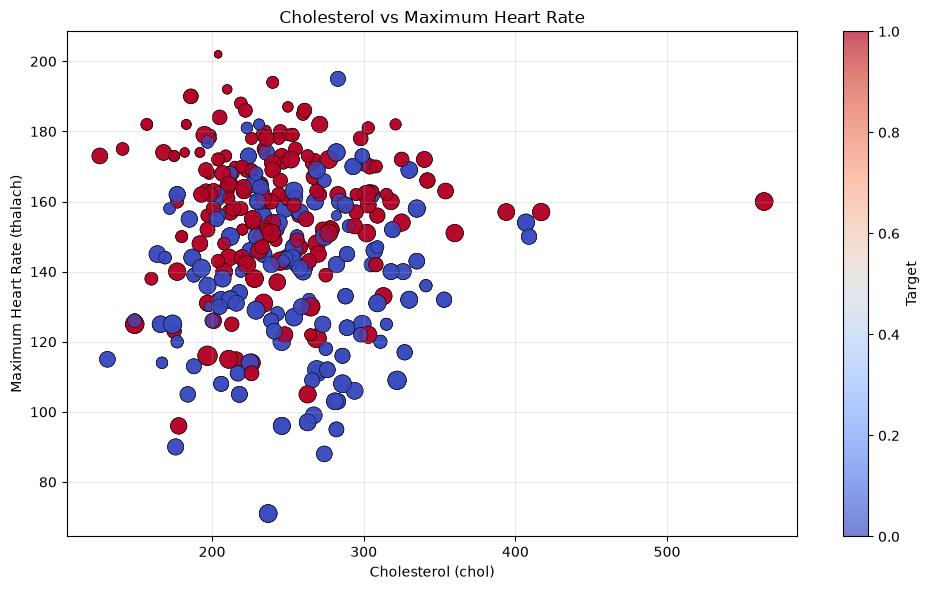

In [5]:
chol = list(plot_df["chol"])
thalach = list(plot_df["thalach"])
targets = list(plot_df["target"])

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    chol,
    thalach,
    s=point_sizes,
    c=targets,
    cmap="coolwarm",
    alpha=0.7,
    edgecolors="black",
    linewidths=0.4
)

plt.colorbar(scatter, label="Target")
plt.xlabel("Cholesterol (chol)")
plt.ylabel("Maximum Heart Rate (thalach)")
plt.title("Cholesterol vs Maximum Heart Rate")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

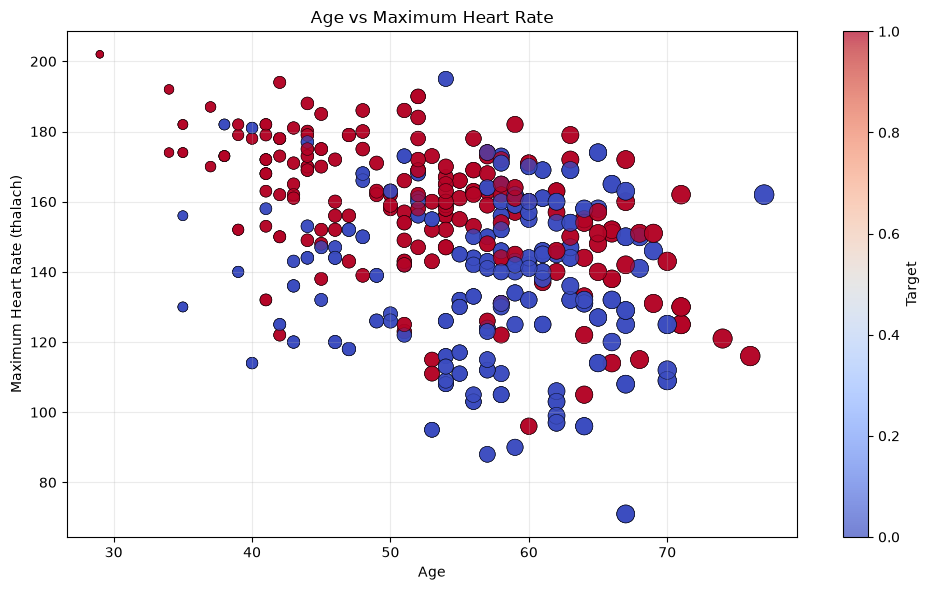

In [6]:
age_values = list(plot_df["age"])

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    age_values,
    thalach,
    s=point_sizes,
    c=targets,
    cmap="coolwarm",
    alpha=0.7,
    edgecolors="black",
    linewidths=0.4
)

plt.colorbar(scatter, label="Target")
plt.xlabel("Age")
plt.ylabel("Maximum Heart Rate (thalach)")
plt.title("Age vs Maximum Heart Rate")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

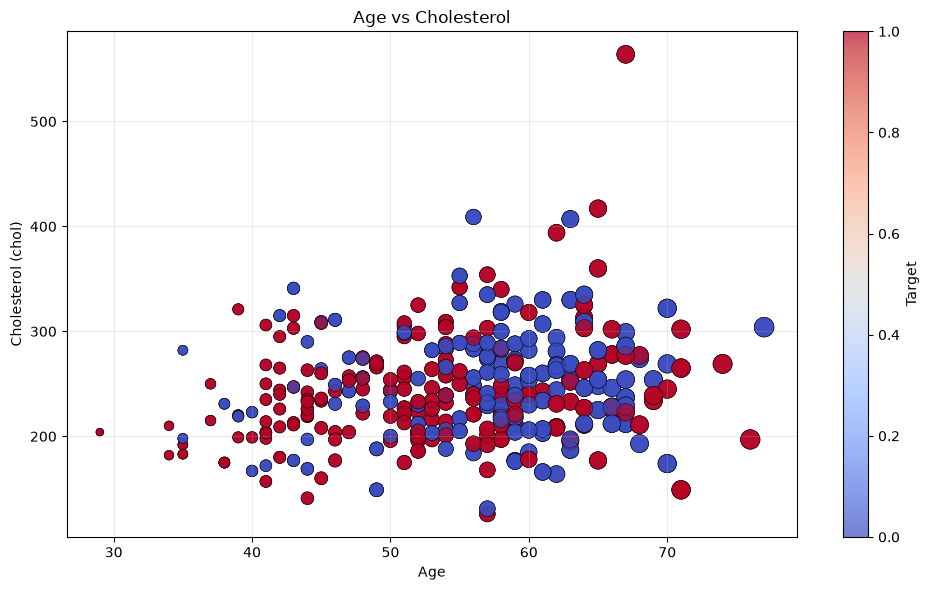

In [7]:
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    age_values,
    chol,
    s=point_sizes,
    c=targets,
    cmap="coolwarm",
    alpha=0.7,
    edgecolors="black",
    linewidths=0.4
)

plt.colorbar(scatter, label="Target")
plt.xlabel("Age")
plt.ylabel("Cholesterol (chol)")
plt.title("Age vs Cholesterol")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Conclusion

In this task, advanced scatter plots were created to explore relationships
between age, cholesterol, and maximum heart rate. Point sizes were
manually scaled according to age, while colors represented the target
class. These visualizations help identify patterns and differences in
the dataset. However, the plots alone do not establish causation or
provide a medical diagnosis.